# Knowledge-Embedded Latent Projection Demo

This notebook demonstrates the Knowledge-Embedded Latent Projection (KELP) method, which incorporates external embeddings (e.g., pre-trained feature embeddings) to improve representation learning.

## Overview

The demo runs three approaches:
1. **Baseline**: Standard generalized latent factor model using gradient descent algorithm
2. **Knowledge-Embedded Latent Projection (KELP)**: KELP method using projected gradient descent by manually specifying a kernel.
3. **Data-Driven Kernel Selection**: Select the optimal kernel using data-driven method

## Setup

In [1]:
# Import required libraries
import numpy as np
from utils import oppo, generate_data
from method import fit_kernel_pca, usvt_initialization, PGD, kernel_selection, kernel_pca

In [2]:
# Generate synthetic simulation data
# Parameters
n = 200      # Number of samples
p = 4000     # Number of features
d = 50       # Dimensionality of the external embeddings (E)
r = 8        # Dimensionality of the latent space
rho = -1.5   # Sparsity parameter
data_kernel = 'linear'  # Type of relationship: 'linear' or 'nonlinear'
seed = 2025  # Random seed for reproducibility

# Generate data
E, rho_true, alpha_true, U_true, V_true, Y = generate_data(
    n, p, d, r, rho, v_alpha=1, func_type=data_kernel, seed=seed
)

# Compute true parameter matrix Theta = U V^T + rho + alpha 1^T
one_p = np.ones((p, 1))
Theta_true = np.dot(U_true, V_true.T) + rho_true + alpha_true @ one_p.T

print(f"Data generated: {n} samples × {p} features")
print(f"Mean of observed matrix Y: {np.mean(Y):.4f}") 

Data generated: 200 samples × 4000 features
Mean of observed matrix Y: 0.2301


## 1. Baseline: Standard Generalized Latent Factor Model

This section implements the baseline method using a standard generalized latent factor model with gradient descent algorithm. This method does **not** use external embeddings and serves as a baseline for comparison.

In [3]:
# Step 1: Initialize using USVT (Universal Singular Value Thresholding)
rho_init, alpha_init, U_init, V_init, Theta_init = usvt_initialization(Y, r)

# Evaluate initialization quality
# Note: U and V are identifiable up to an orthogonal transformation, so we use the Procrustes distance
error_U_init = oppo(U_true, U_init) / np.linalg.norm(U_true, 'fro')
error_V_init = oppo(V_true, V_init) / np.linalg.norm(V_true, 'fro')
error_Theta_init = np.linalg.norm(Theta_true - Theta_init, 'fro') / np.linalg.norm(Theta_true, 'fro')

print("=== Initialization Results (Baseline) ===")
print(f"Relative error for U: {error_U_init:.2e}")
print(f"Relative error for V: {error_V_init:.2e}")
print(f"Relative error for Theta: {error_Theta_init:.2e}\n")

# Step 2: Run PGD optimization
max_iter = 2000
tol = 1e-3
tau = 0.5  # Step size

print("Running PGD optimization...")
rho_1, alpha_1, U_1, V_1, Theta_1 = PGD(Y, tol, max_iter, tau, rho_init, alpha_init, U_init, V_init)

# Evaluate final results
error_U_1 = oppo(U_true, U_1) / np.linalg.norm(U_true, 'fro')
error_V_1 = oppo(V_true, V_1) / np.linalg.norm(V_true, 'fro')
error_Theta_1 = np.linalg.norm(Theta_true - Theta_1, 'fro') / np.linalg.norm(Theta_true, 'fro')

print("\n=== Final Results (Baseline PGD) ===")
print(f"Relative error for U: {error_U_1:.2e}")
print(f"Relative error for V: {error_V_1:.2e}")
print(f"Relative error for Theta: {error_Theta_1:.2e}")


=== Initialization Results (Baseline) ===
Relative error for U: 1.14e+00
Relative error for V: 1.08e+00
Relative error for Theta: 7.80e-01

Running PGD optimization...
Iteration: 0
Loss: 0.4846702070528243
Iteration: 100
Loss: 0.4645193220687431
Iteration: 200
Loss: 0.45747050416473767
Iteration: 300
Loss: 0.4516018926420537
Iteration: 400
Loss: 0.44655709206567723
Iteration: 500
Loss: 0.4427474844710204
Iteration: 600
Loss: 0.44004951607254816
Iteration: 700
Loss: 0.4381603012104726
Iteration: 800
Loss: 0.4368227505319324
Iteration: 900
Loss: 0.43584827723378866
Iteration: 1000
Loss: 0.435107773419453
Iteration: 1100
Loss: 0.4345177040543327
Iteration: 1200
Loss: 0.43402580924320516
Iteration: 1300
Loss: 0.43360009442909403
Iteration: 1400
Loss: 0.4332214431307988
Iteration: 1500
Loss: 0.4328787739019712
Iteration: 1600
Loss: 0.43256583350134103
Iteration: 1700
Loss: 0.4322790883817885
Iteration: 1800
Loss: 0.43201638274683757
Iteration: 1900
Loss: 0.4317761326509226

=== Final Result

## 2. Knowledge-Embedded Latent Projection (KELP)

This section demonstrates the Knowledge-Embedded Latent Projection (KELP) method using projected gradient descent by manually specifying a kernel. The method incorporates external embeddings `E` through kernel PCA to improve representation learning.

Kernel PCA Results:
  - Selected dimension q: 248
  - Explained variance: 0.9502


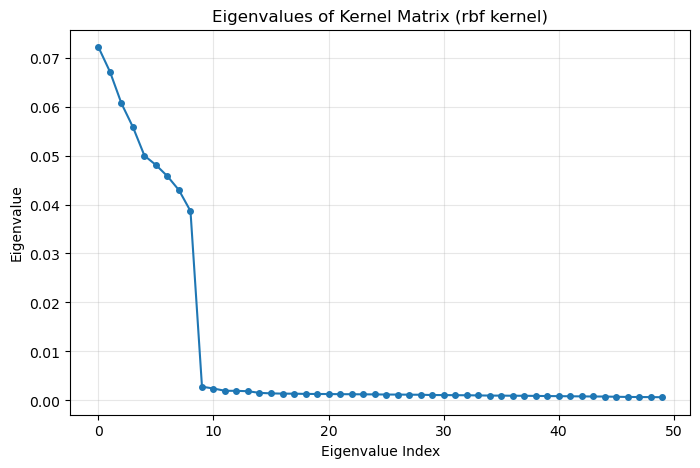

In [4]:
# Step 1: Fit kernel PCA to the external embeddings E
# This transforms the external embeddings into a feature space that captures nonlinear relationships
import matplotlib.pyplot as plt

kernel_type = 'rbf'
kernel_params = {'gamma': 0.01}

Phi, q, info = fit_kernel_pca(E, kernel_type=kernel_type, kernel_params=kernel_params)

print(f"Kernel PCA Results:")
print(f"  - Selected dimension q: {q}")
print(f"  - Explained variance: {info['explained_variance']:.4f}")

# Visualize eigenvalues
plt.figure(figsize=(8, 5))
plt.plot(info['eigvals'][:min(q, 50)], 'o-', markersize=4)
plt.xlabel('Eigenvalue Index')
plt.ylabel('Eigenvalue')
plt.title(f'Eigenvalues of Kernel Matrix ({kernel_type} kernel)')
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
# Step 2: Initialize using USVT with knowledge from external embeddings
# The Phi matrix constrains V to lie in the column space of the kernel PCA features
rho_init, alpha_init, U_init, V_init, Theta_init = usvt_initialization(Y, r, Phi)

# Alternative: You can also initialize from baseline results
# proj = np.linalg.solve(Phi.T @ Phi, Phi.T)
# rho_init = rho_1
# alpha_init = alpha_1
# U_init = U_1
# V_init = Phi @ (proj @ V_1)

# Evaluate initialization quality
error_U_init = oppo(U_true, U_init) / np.linalg.norm(U_true, 'fro')
error_V_init = oppo(V_true, V_init) / np.linalg.norm(V_true, 'fro')
error_Theta_init = np.linalg.norm(Theta_true - Theta_init, 'fro') / np.linalg.norm(Theta_true, 'fro')

print("=== Initialization Results (Knowledge-Embedded) ===")
print(f"Relative error for U: {error_U_init:.2e}")
print(f"Relative error for V: {error_V_init:.2e}")
print(f"Relative error for Theta: {error_Theta_init:.2e}\n")

# Step 3: Run knowledge-embedded PGD
# The Phi matrix ensures V stays in the kernel PCA feature space during optimization
max_iter = 2000
tol = 1e-3
tau = 1.0  # Step size (can be larger when using external knowledge)

print("Running Knowledge-Embedded PGD optimization...")
rho_2, alpha_2, U_2, V_2, Theta_2 = PGD(Y, tol, max_iter, tau, rho_init, alpha_init, U_init, V_init, Phi)

# Evaluate final results
error_U_2 = oppo(U_true, U_2) / np.linalg.norm(U_true, 'fro')
error_V_2 = oppo(V_true, V_2) / np.linalg.norm(V_true, 'fro')
error_Theta_2 = np.linalg.norm(Theta_true - Theta_2, 'fro') / np.linalg.norm(Theta_true, 'fro')

print("\n=== Final Results (Knowledge-Embedded PGD) ===")
print(f"Relative error for U: {error_U_2:.2e}")
print(f"Relative error for V: {error_V_2:.2e}")
print(f"Relative error for Theta: {error_Theta_2:.2e}")

=== Initialization Results (Knowledge-Embedded) ===
Relative error for U: 9.93e-01
Relative error for V: 7.88e-01
Relative error for Theta: 6.20e-01

Running Knowledge-Embedded PGD optimization...
Iteration: 0
Loss: 0.4895636169771519
Iteration: 100
Loss: 0.4659163355343815
Iteration: 200
Loss: 0.45572772486201624
Iteration: 300
Loss: 0.45247156473550904
Iteration: 400
Loss: 0.4512795890184292
Iteration: 500
Loss: 0.45063727479038673
Iteration: 600
Loss: 0.4502188718798631
Iteration: 700
Loss: 0.44998171626481165
Iteration: 800
Loss: 0.4498672477234793
Iteration: 900
Loss: 0.44981540931597547
Iteration: 1000
Loss: 0.4497920525709528
Iteration: 1100
Loss: 0.4497813477468746
Iteration: 1200
Loss: 0.449776323138254
Iteration: 1300
Loss: 0.44977390513973864
Iteration: 1400
Loss: 0.44977271337138575
Iteration: 1500
Loss: 0.4497721128546092
Iteration: 1600
Loss: 0.44977180413018497
Iteration: 1700
Loss: 0.4497716425308069
Iteration: 1800
Loss: 0.44977155657493756
Iteration: 1900
Loss: 0.4497

## 3. Data-Driven Kernel Selection

This section demonstrates how to select the optimal kernel using a data-driven method. Instead of manually choosing a kernel, the method automatically evaluates multiple kernels on a validation set and selects the one with the best performance.

In [6]:
# Define candidate kernels to evaluate
# - rbf1, rbf2, rbf3: RBF kernels with different gamma parameters (0.001, 0.01, 0.1)
# - linear: Linear kernel
kernel_list = ['rbf1', 'rbf2', 'rbf3', 'linear']

# Run kernel selection
# This procedure:
# 1. Masks a portion of the data (mask_rate=0.1) as validation set
# 2. Trains models with each kernel on the training set
# 3. Evaluates performance on the validation set
# 4. Selects the kernel with the lowest validation loss
print("Running kernel selection...")
print("This may take a few minutes as it evaluates multiple kernels.\n")

kernel_selected = kernel_selection(
    Y, E, kernel_list, n, p, r, tol, 
    max_iter=500, tau=tau, 
    mask_rate=0.1, seed=1
)

print(f"\n✓ Selected kernel: {kernel_selected}")

Running kernel selection...
This may take a few minutes as it evaluates multiple kernels.

0.09981875
Initial loss: 0.05068552039380047
Iteration: 0
Loss: 0.44281382575131795
Iteration: 100
Loss: 0.42050464985177877
Iteration: 200
Loss: 0.4038533435910451
Iteration: 300
Loss: 0.39490689100252924
Iteration: 400
Loss: 0.3906588786256631
Loss after PGD: 0.04967560043414435
Kernel: rbf1 q: 32 explained_variance: 0.9507311714404799
Iteration: 0
Loss: 0.41652813942402295
Iteration: 100
Loss: 0.4103722826182094
Iteration: 200
Loss: 0.4092692217378414
Iteration: 300
Loss: 0.4088516793813881
Iteration: 400
Loss: 0.4087009909447799
Loss after PGD: 0.045728394099286876
Kernel: rbf2 q: 248 explained_variance: 0.9502268017500148
Iteration: 0
Loss: 0.41278595336775425
Iteration: 100
Loss: 0.4071050560876357
Iteration: 200
Loss: 0.4057508768309688
Iteration: 300
Loss: 0.4050537239738734
Iteration: 400
Loss: 0.4047339173652183
Loss after PGD: 0.045522915783971885
Kernel: rbf3 q: 3091 explained_varianc

In [7]:
# Run final model with the selected kernel
if kernel_selected == "Baseline":
    # If baseline was selected, use standard PGD without external embeddings
    print("Using baseline method (no external embeddings)...")
    rho_3, alpha_3, U_3, V_3, Theta_3 = PGD(Y, tol, max_iter, tau, rho_init, alpha_init, U_init, V_init)
else:
    # Otherwise, use the selected kernel for knowledge-embedded PGD
    print(f"Using knowledge-embedded method with {kernel_selected} kernel...")
    Phi_selected, q, info = kernel_pca(E, kernel_selected)
    print(f"  - Kernel PCA dimension q: {q}")
    print(f"  - Explained variance: {info['explained_variance']:.4f}\n")
    
    rho_init, alpha_init, U_init, V_init, Theta_init = usvt_initialization(Y, r, Phi_selected)
    rho_3, alpha_3, U_3, V_3, Theta_3 = PGD(Y, tol, max_iter, tau, rho_init, alpha_init, U_init, V_init, Phi_selected)

# Evaluate final results
error_U_3 = oppo(U_true, U_3) / np.linalg.norm(U_true, 'fro')
error_V_3 = oppo(V_true, V_3) / np.linalg.norm(V_true, 'fro')
error_Theta_3 = np.linalg.norm(Theta_true - Theta_3, 'fro') / np.linalg.norm(Theta_true, 'fro')

print("\n=== Final Results (Selected Kernel) ===")
print(f"Relative error for U: {error_U_3:.2e}")
print(f"Relative error for V: {error_V_3:.2e}")
print(f"Relative error for Theta: {error_Theta_3:.2e}")


Using knowledge-embedded method with linear kernel...
  - Kernel PCA dimension q: 44
  - Explained variance: 0.9905

Iteration: 0
Loss: 0.4901149930717889
Iteration: 100
Loss: 0.462346948255227
Iteration: 200
Loss: 0.4550846046517026
Iteration: 300
Loss: 0.45336541342028847
Iteration: 400
Loss: 0.4526666519074165
Iteration: 500
Loss: 0.4521655779252402
Iteration: 600
Loss: 0.4518431613407991
Iteration: 700
Loss: 0.4516992785702368
Iteration: 800
Loss: 0.4516448238373084
Iteration: 900
Loss: 0.45162447181433296
Iteration: 1000
Loss: 0.4516166363319911
Iteration: 1100
Loss: 0.45161350560808766
Iteration: 1200
Loss: 0.4516122082080495
Iteration: 1300
Loss: 0.4516116522712486
Iteration: 1400
Loss: 0.4516114068870691
Iteration: 1500
Loss: 0.4516112957476049
Iteration: 1600
Loss: 0.45161124427986854
Iteration: 1700
Loss: 0.451611219988599
Iteration: 1800
Loss: 0.4516112083370303
Iteration: 1900
Loss: 0.45161120267113036

=== Final Results (Selected Kernel) ===
Relative error for U: 1.61e-01


## 4. Results Comparison

Compare the performance of all three methods:

=== Performance Comparison ===
                      Method  U Error  V Error  Theta Error
                Baseline PGD 0.591631 0.745301     0.467709
Knowledge-Embedded PGD (RBF) 0.164721 0.172453     0.104894
    Selected Kernel (linear) 0.160892 0.147555     0.096611


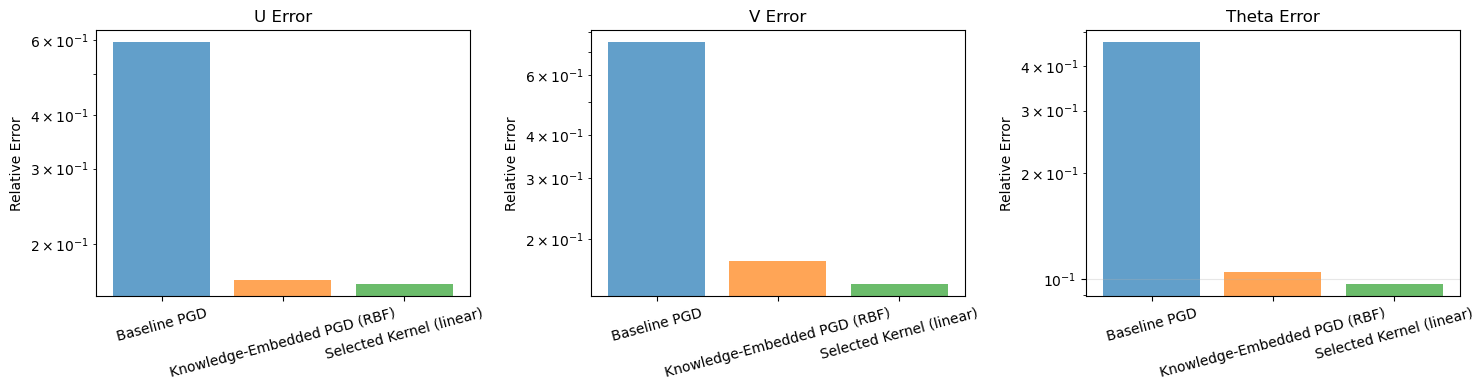

In [8]:
# Compare results across all methods
import pandas as pd

results = pd.DataFrame({
    'Method': ['Baseline PGD', 'Knowledge-Embedded PGD (RBF)', f'Selected Kernel ({kernel_selected})'],
    'U Error': [error_U_1, error_U_2, error_U_3],
    'V Error': [error_V_1, error_V_2, error_V_3],
    'Theta Error': [error_Theta_1, error_Theta_2, error_Theta_3]
})

print("=== Performance Comparison ===")
print(results.to_string(index=False))

# Visualize comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = ['U Error', 'V Error', 'Theta Error']
for idx, metric in enumerate(metrics):
    axes[idx].bar(results['Method'], results[metric], alpha=0.7, color=['#1f77b4', '#ff7f0e', '#2ca02c'])
    axes[idx].set_ylabel('Relative Error')
    axes[idx].set_title(metric)
    axes[idx].tick_params(axis='x', rotation=15)
    axes[idx].set_yscale('log')
    axes[idx].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()